# B1 — Lingkungan Kerja dan Struktur Citra

Evaluasi Praktikum P1–P4 Computer Vision
SIMUTEH — Klasifikasi Kualitas Daun Teh

In [ ]:
import sys
sys.path.append("./src")

import cv2
import numpy as np
import skimage
import matplotlib.pyplot as plt

from utils_cv import baca, tampil

print("OpenCV", cv2.__version__, "| NumPy", np.__version__,
      "| scikit-image", skimage.__version__)

img = baca("./data/sintetis/citra/teh_041.png")

print("shape:", img.shape, "dtype:", img.dtype)
print("min-maks:", img.min(), img.max())
print("piksel (y=100, x=200) dalam urutan BGR:", img[100, 200])

# tampilkan citra TANPA dan DENGAN konversi BGR ke RGB
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title("Tanpa konversi (salah)")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Dengan konversi BGR ke RGB")
plt.axis("off")

plt.tight_layout()
plt.savefig("./hasil/b1_bgr_rgb.png")
plt.show()

OpenCV 4.12.0 | NumPy 2.2.6 | scikit-image 0.26.0


FileNotFoundError: Citra tidak ditemukan: ../data/sintetis/citra/teh_041.png

Problem Statement

Bagi pekerja penyortiran daun teh yang menghadapi kesulitan dalam membedakan kualitas daun berdasarkan gejala bercak, kami membangun sistem visi komputer SIMUTEH yang menerima citra daun teh dari kamera smartphone dan menghasilkan kelas kualitas berupa Sehat, Bercak Ringan, atau Bercak Berat serta persentase area bercak, sehingga proses penyortiran dapat dilakukan secara lebih konsisten dan cepat dengan tetap menjadikan pekerja sebagai pengambil keputusan akhir.

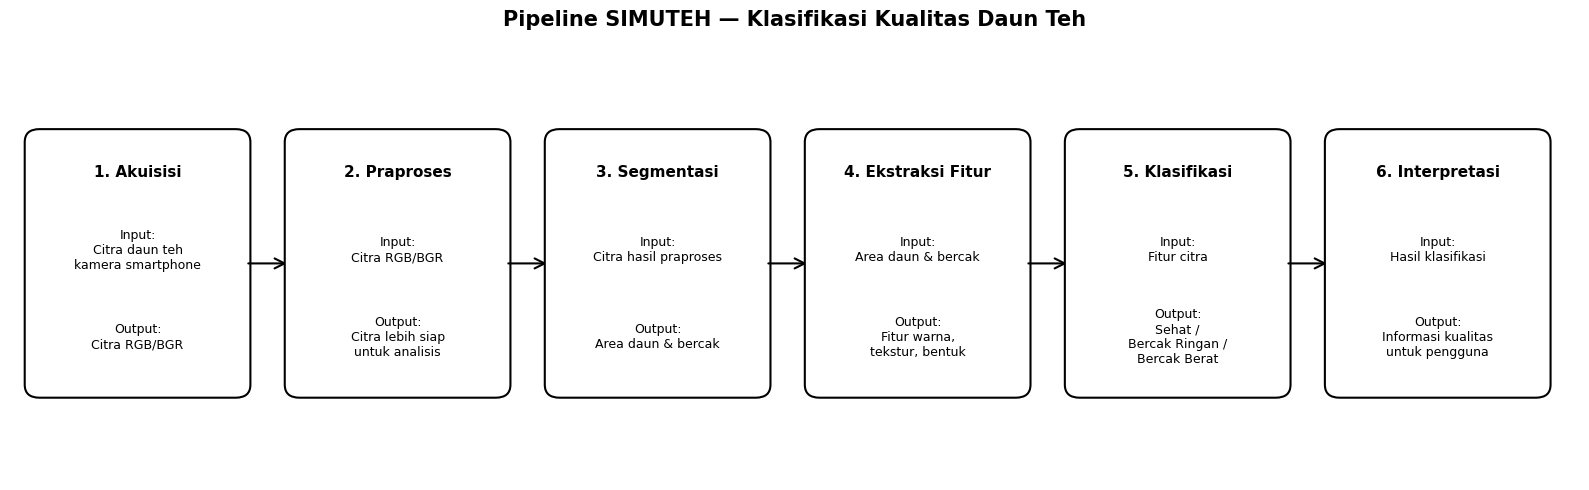

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(16, 5))
ax.set_xlim(0, 16)
ax.set_ylim(0, 5)
ax.axis("off")

tahapan = [
    ("1. Akuisisi",
     "Input:\nCitra daun teh\nkamera smartphone",
     "Output:\nCitra RGB/BGR"),

    ("2. Praproses",
     "Input:\nCitra RGB/BGR",
     "Output:\nCitra lebih siap\nuntuk analisis"),

    ("3. Segmentasi",
     "Input:\nCitra hasil praproses",
     "Output:\nArea daun & bercak"),

    ("4. Ekstraksi Fitur",
     "Input:\nArea daun & bercak",
     "Output:\nFitur warna,\ntekstur, bentuk"),

    ("5. Klasifikasi",
     "Input:\nFitur citra",
     "Output:\nSehat /\nBercak Ringan /\nBercak Berat"),

    ("6. Interpretasi",
     "Input:\nHasil klasifikasi",
     "Output:\nInformasi kualitas\nuntuk pengguna")
]

x_positions = [0.2, 2.85, 5.5, 8.15, 10.8, 13.45]

for i, ((judul, input_text, output_text), x) in enumerate(zip(tahapan, x_positions)):
    box = FancyBboxPatch(
        (x, 1.0), 2.2, 3.0,
        boxstyle="round,pad=0.05,rounding_size=0.15",
        linewidth=1.5,
        edgecolor="black",
        facecolor="white"
    )
    ax.add_patch(box)

    ax.text(
        x + 1.1, 3.55,
        judul,
        ha="center",
        va="center",
        fontsize=11,
        fontweight="bold"
    )

    ax.text(
        x + 1.1, 2.65,
        input_text,
        ha="center",
        va="center",
        fontsize=9
    )

    ax.text(
        x + 1.1, 1.65,
        output_text,
        ha="center",
        va="center",
        fontsize=9
    )

    if i < len(tahapan) - 1:
        arrow = FancyArrowPatch(
            (x + 2.2, 2.5),
            (x + 2.65, 2.5),
            arrowstyle="->",
            mutation_scale=18,
            linewidth=1.5,
            color="black"
        )
        ax.add_patch(arrow)

ax.set_title(
    "Pipeline SIMUTEH — Klasifikasi Kualitas Daun Teh",
    fontsize=15,
    fontweight="bold",
    pad=15
)

plt.tight_layout()
plt.savefig("./hasil/b1_pipeline.png", dpi=300, bbox_inches="tight")
plt.show()

| Aspek | Risiko pada SIMUTEH | Mitigasi |
|---|---|---|
| Privasi citra | Citra daun dapat mengandung latar atau informasi lingkungan pengguna. | Membatasi pengambilan citra pada objek yang diperlukan dan menghapus informasi yang tidak diperlukan. |
| Bias dan keadilan | Kondisi pencahayaan, varietas daun, dan kualitas citra dapat menyebabkan hasil klasifikasi berbeda. | Menggunakan variasi data yang mewakili kondisi penggunaan dan mengevaluasi hasil pada setiap kondisi. |
| Transparansi | Pengguna dapat menganggap hasil klasifikasi sistem sebagai keputusan yang mutlak. | Menampilkan kelas dan informasi pendukung serta menjelaskan bahwa hasil merupakan bantuan pengambilan keputusan. |
| Keamanan data | Dataset dan hasil pengambilan citra dapat disalahgunakan jika tidak dikelola dengan baik. | Membatasi akses data dan menyimpan data sesuai kebutuhan sistem. |
| Dampak sosial | Kesalahan klasifikasi dapat memengaruhi proses penyortiran kualitas daun. | Menjadikan pekerja sebagai pengambil keputusan akhir dan melakukan evaluasi kesalahan klasifikasi. |
| Keterlacakan | Sulit mengetahui data dan proses yang menghasilkan suatu prediksi. | Menyimpan parameter, versi kode, dan hasil eksperimen secara terstruktur. |